# E-Commerce Sales & Customer Analytics

## Project Overview

In this project, I analyze transaction data from an online retailer to
understand sales trends, customer behavior, product performance and
country-level sales.

The analysis is carried out using Python and Pandas, followed by SQL
and Power BI.

### Questions I want to answer

- How much revenue was generated?
- How does revenue change over time?
- Which customers generate the most revenue?
- How many customers are repeat customers?
- Which products sell the most?
- Which countries generate the most revenue?
- Which customers have been inactive for a long time?

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

## 1. Load the Dataset
The dataset contains two sheets covering different periods. I will
load both sheets and combine them before starting the analysis.

In [3]:
# load the sourcefile
DATA_PATH = Path('online_retail_II.xlsx')

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'{DATA_PATH} was not found. Place online_retail_II.xlsx in the project folder.'
    )

print(DATA_PATH.resolve())

C:\Users\SWETA RAJPUT\OneDrive\Desktop\projects\online_retail_II.xlsx


In [4]:
df_2009_2010 = pd.read_excel(DATA_PATH, sheet_name='Year 2009-2010')
df_2010_2011 = pd.read_excel(DATA_PATH, sheet_name='Year 2010-2011')

print('2009-2010:', df_2009_2010.shape)
print('2010-2011:', df_2010_2011.shape)

2009-2010: (525461, 8)
2010-2011: (541910, 8)


In [5]:
df = pd.concat([df_2009_2010, df_2010_2011], ignore_index=True)

df.shape

(1067371, 8)

In [6]:
df.head()

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[ns]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 65.1+ MB


## 2. Data Quality Check

Before cleaning the data, I checked missing values, cancellations,
negative quantities, zero/negative prices and unusual invoice types.

In [8]:
# Missing values
missing_summary = pd.DataFrame({
    'Missing_Count': df.isna().sum(),
    'Missing_Percentage': (df.isna().mean() * 100).round(2)
})

missing_summary

,Missing_Count,Missing_Percentage
Invoice,0,0.00
StockCode,0,0.00
Description,4382,0.41
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Customer ID,243007,22.77
Country,0,0.00


In [9]:
# Date range
(df['InvoiceDate'].min(), df['InvoiceDate'].max())

(Timestamp('2009-12-01 07:45:00'), Timestamp('2011-12-09 12:50:00'))

In [10]:
# Cancellation records: invoices beginning with C
is_cancelled = df['Invoice'].astype(str).str.startswith('C')

cancellation_summary = pd.DataFrame({
    'Cancelled': [is_cancelled.sum(), (~is_cancelled).sum()],
    'Percentage': [is_cancelled.mean() * 100, (~is_cancelled).mean() * 100]
}, index=['Cancelled invoices', 'Other invoices'])

cancellation_summary.round(2)

,Cancelled,Percentage
Cancelled invoices,19494,1.83
Other invoices,1047877,98.17


In [11]:
# Negative quantities
negative_quantity_count = (df['Quantity'] < 0).sum()
negative_quantity_count

np.int64(22950)

In [12]:
# Non-positive prices
non_positive_price_count = (df['Price'] <= 0).sum()
non_positive_price_count

np.int64(6207)

In [13]:
# Negative quantities that are not cancellation invoices
non_cancelled_negative = df[(~is_cancelled) & (df['Quantity'] < 0)]

non_cancelled_negative[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']].head(20)

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
263,489464,21733,85123a mixed,-96,0.00,NaN,United Kingdom
283,489463,71477,short,-240,0.00,NaN,United Kingdom
284,489467,85123A,21733 mixed,-192,0.00,NaN,United Kingdom
470,489521,21646,NaN,-50,0.00,NaN,United Kingdom
3114,489655,20683,NaN,-44,0.00,NaN,United Kingdom
3162,489660,35956,lost,-1043,0.00,NaN,United Kingdom
3168,489663,35605A,damages,-117,0.00,NaN,United Kingdom
4296,489806,18010,NaN,-770,0.00,NaN,United Kingdom
4538,489820,21133,invcd as 84879?,-720,0.00,NaN,United Kingdom
4566,489821,85049G,NaN,-240,0.00,NaN,United Kingdom


In [14]:
# Positive-quantity, zero-price records
positive_zero_price = df[(df['Quantity'] > 0) & (df['Price'] == 0)]

positive_zero_price['Description'].value_counts().head(20)

Description
check                                  39
found                                  28
OWL DOORSTOP                           15
adjustment                             14
POLYESTER FILLER PAD 45x45cm           12
amazon                                 11
IVORY KITCHEN SCALES                   10
POLYESTER FILLER PAD 40x40cm           10
FRENCH BLUE METAL DOOR SIGN 1          10
FRENCH BLUE METAL DOOR SIGN 8           9
BOX OF 24 COCKTAIL PARASOLS             9
Found                                   9
PICNIC BASKET WICKER LARGE              9
AIRLINE BAG VINTAGE WORLD CHAMPION      9
?                                       9
RED KITCHEN SCALES                      9
FRENCH BLUE METAL DOOR SIGN No          8
RECIPE BOX PANTRY YELLOW DESIGN         8
CHILDS GARDEN SPADE BLUE                8
FRENCH BLUE METAL DOOR SIGN 4           8
Name: count, dtype: int64

In [15]:
# Invoice prefixes
invoice_prefix_summary = df['Invoice'].astype(str).str[0].value_counts()
invoice_prefix_summary

Invoice
5    939382
4    108489
C     19494
A         6
Name: count, dtype: int64

In [16]:
# A-prefixed invoices are accounting adjustments in this dataset.
adjustments = df[df['Invoice'].astype(str).str.startswith('A')]
adjustments[['Invoice', 'StockCode', 'Description', 'Quantity', 'Price', 'Customer ID', 'Country']]

,Invoice,StockCode,Description,Quantity,Price,Customer ID,Country
179403,A506401,B,Adjust bad debt,1,"-53,594.36",NaN,United Kingdom
276274,A516228,B,Adjust bad debt,1,"-44,031.79",NaN,United Kingdom
403472,A528059,B,Adjust bad debt,1,"-38,925.87",NaN,United Kingdom
825443,A563185,B,Adjust bad debt,1,"11,062.06",NaN,United Kingdom
825444,A563186,B,Adjust bad debt,1,"-11,062.06",NaN,United Kingdom
825445,A563187,B,Adjust bad debt,1,"-11,062.06",NaN,United Kingdom


## 3. Data Cleaning

For the sales analysis, I excluded:

- cancellation invoices (`C`)
- accounting adjustment invoices (`A`)
- non-positive quantities
- non-positive prices

Missing Customer IDs are retained because those transactions can still
be used for overall sales analysis.

In [17]:
sales_candidate = (
    ~df['Invoice'].astype(str).str.startswith(('C', 'A'))
    & (df['Quantity'] > 0)
    & (df['Price'] > 0)
)

df_sales = df.loc[sales_candidate].copy()

print('Rows before exact-duplicate removal:', len(df_sales))
print('Exact duplicate rows:', df_sales.duplicated().sum())

Rows before exact-duplicate removal: 1041669
Exact duplicate rows: 33757


In [18]:
df_sales = df_sales.drop_duplicates().copy()

print('Rows after exact-duplicate removal:', len(df_sales))
print('Remaining exact duplicates:', df_sales.duplicated().sum())

Rows after exact-duplicate removal: 1007912
Remaining exact duplicates: 0


In [19]:
# check the cleaned data
cleaning_check = {
    'Minimum Quantity': df_sales['Quantity'].min(),
    'Minimum Price': df_sales['Price'].min(),
    'Cancellation/Adjustment Rows': df_sales['Invoice'].astype(str).str.startswith(('C', 'A')).sum(),
    'Missing Customer IDs': df_sales['Customer ID'].isna().sum()
}

pd.Series(cleaning_check)

Minimum Quantity                     1.00
Minimum Price                        0.00
Cancellation/Adjustment Rows         0.00
Missing Customer IDs           228,487.00
dtype: float64

In [20]:
# Create the core analytical fields
df_sales['Revenue'] = df_sales['Quantity'] * df_sales['Price']
df_sales['Month'] = df_sales['InvoiceDate'].dt.to_period('M')
df_sales['Year'] = df_sales['InvoiceDate'].dt.year

df_sales[['Quantity', 'Price', 'Revenue', 'Month', 'Year']].head()

,Quantity,Price,Revenue,Month,Year
0,12,6.95,83.40,2009-12,2009
1,12,6.75,81.00,2009-12,2009
2,12,6.75,81.00,2009-12,2009
3,48,2.10,100.80,2009-12,2009
4,24,1.25,30.00,2009-12,2009


## 4. sales and revenue analysis

In [21]:
# Core sales KPIs
sales_kpis = pd.Series({
    'Total Revenue': df_sales['Revenue'].sum(),
    'Total Units Sold': df_sales['Quantity'].sum(),
    'Total Orders': df_sales['Invoice'].nunique(),
    'Average Order Value': df_sales['Revenue'].sum() / df_sales['Invoice'].nunique(),
    'Average Units per Order': df_sales['Quantity'].sum() / df_sales['Invoice'].nunique()
})

sales_kpis

Total Revenue             20,465,198.39
Total Units Sold          11,205,147.00
Total Orders                  40,076.00
Average Order Value              510.66
Average Units per Order          279.60
dtype: float64

In [22]:
# Monthly revenue
monthly_revenue = df_sales.groupby('Month')['Revenue'].sum()
monthly_revenue

Month
2009-12     822,483.95
2010-01     651,155.11
2010-02     551,504.73
2010-03     830,915.26
2010-04     678,875.25
2010-05     657,705.50
2010-06     749,537.31
2010-07     648,810.27
2010-08     695,251.91
2010-09     921,696.99
2010-10   1,161,902.22
2010-11   1,464,293.14
2010-12     821,452.73
2011-01     689,811.61
2011-02     522,545.56
2011-03     716,215.26
2011-04     536,968.49
2011-05     769,296.61
2011-06     760,547.01
2011-07     718,076.12
2011-08     746,779.32
2011-09   1,056,435.19
2011-10   1,151,263.73
2011-11   1,503,866.78
2011-12     637,808.33
Freq: M, Name: Revenue, dtype: float64

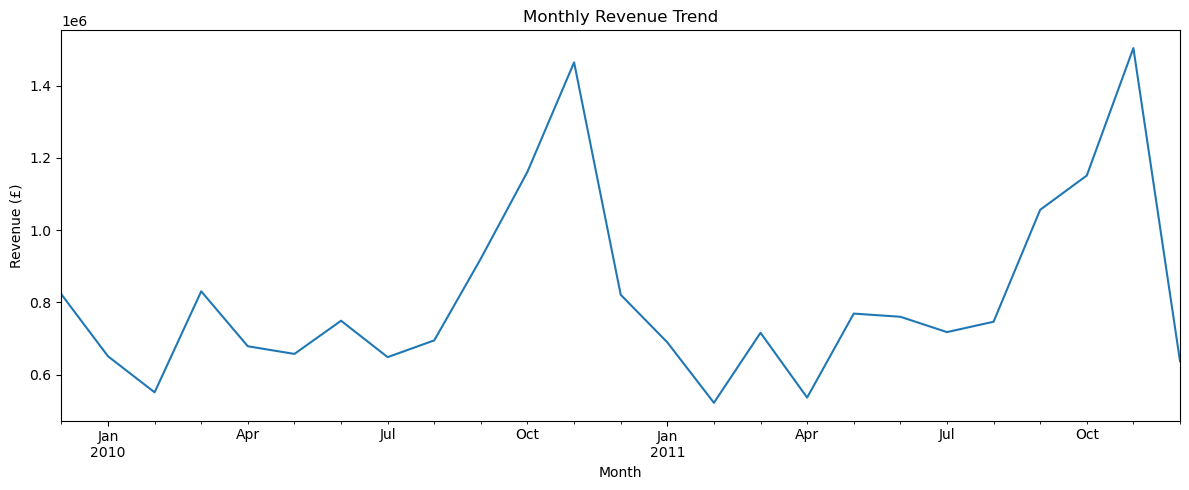

In [49]:
monthly_revenue.plot(figsize=(12, 5))
plt.title('Monthly Revenue Trend')
plt.xlabel('Month')
plt.ylabel('Revenue (£)')
plt.tight_layout()
plt.show()

### Observation

Revenue was highest in November 2011 and lowest in February 2011.There are also noticeable increases during September–November in both
years.

In [24]:
# Monthly orders
monthly_orders = df_sales.groupby('Month')['Invoice'].nunique()
monthly_orders

Month
2009-12    1682
2010-01    1105
2010-02    1201
2010-03    1681
2010-04    1462
2010-05    1500
2010-06    1645
2010-07    1529
2010-08    1425
2010-09    1839
2010-10    2301
2010-11    2747
2010-12    1559
2011-01    1086
2011-02    1100
2011-03    1454
2011-04    1246
2011-05    1681
2011-06    1533
2011-07    1475
2011-08    1360
2011-09    1837
2011-10    2040
2011-11    2769
2011-12     819
Freq: M, Name: Invoice, dtype: int64

In [25]:
# Monthly Average Order Value (AOV)
monthly_aov = df_sales.groupby('Month').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique')
)
monthly_aov['AOV'] = monthly_aov['Revenue'] / monthly_aov['Orders']

monthly_aov

,Revenue,Orders,AOV
Month,,,
2009-12,"822,483.95",1682,488.99
2010-01,"651,155.11",1105,589.28
2010-02,"551,504.73",1201,459.20
2010-03,"830,915.26",1681,494.30
2010-04,"678,875.25",1462,464.35
2010-05,"657,705.50",1500,438.47
2010-06,"749,537.31",1645,455.65
2010-07,"648,810.27",1529,424.34
2010-08,"695,251.91",1425,487.90


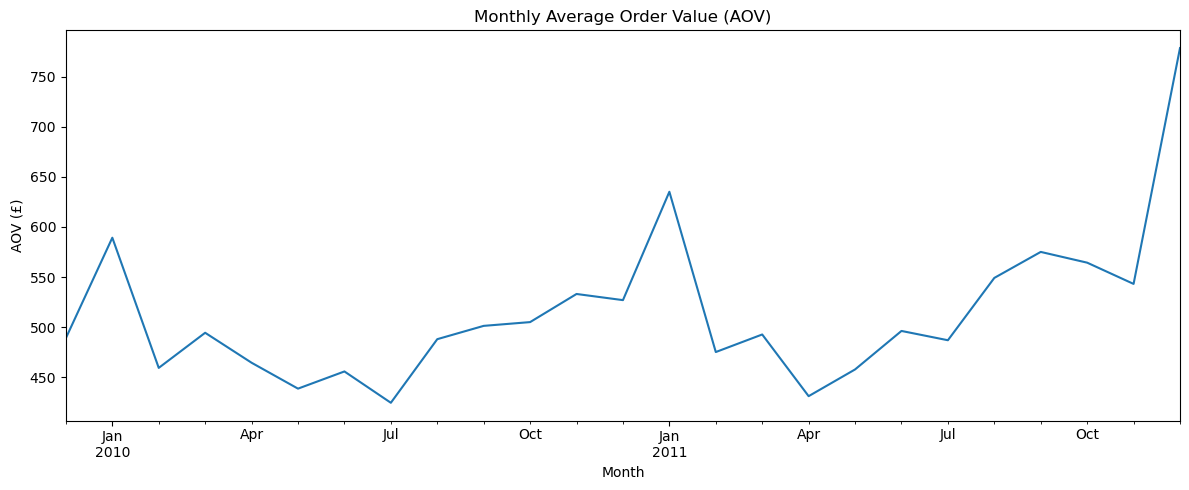

In [50]:
monthly_aov['AOV'].plot(figsize=(12, 5))
plt.title('Monthly Average Order Value (AOV)')
plt.xlabel('Month')
plt.ylabel('AOV (£)')
plt.tight_layout()
plt.show()

In [27]:
# Yearly revenue
# Note: 2009 contains only December and 2011 ends on December 9, so full-year comparisons are not directly like-for-like.
yearly_revenue = df_sales.groupby('Year')['Revenue'].sum()
yearly_revenue

Year
2009     822,483.95
2010   9,833,100.42
2011   9,809,614.01
Name: Revenue, dtype: float64

In [28]:
# 2010 vs 2011 revenue change
revenue_change_2010_2011 = (
    (yearly_revenue.loc[2011] - yearly_revenue.loc[2010])
    / yearly_revenue.loc[2010]
) * 100

revenue_change_2010_2011

np.float64(-0.2388505047978156)

## 5. Customer Analysis

Customer-level analysis uses records with a known Customer ID.Transactions with missing IDs are still included in the overall sales
analysis.

In [29]:
customer_sales = df_sales.dropna(subset=['Customer ID']).copy()

unique_customers = customer_sales['Customer ID'].nunique()
unique_customers

5878

In [30]:
# Orders per identifiable customer
orders_per_customer = (
    customer_sales.groupby('Customer ID')['Invoice']
    .nunique()
)

orders_per_customer.describe()

count   5,878.00
mean        6.29
std        13.01
min         1.00
25%         1.00
50%         3.00
75%         7.00
max       398.00
Name: Invoice, dtype: float64

In [31]:
# Repeat vs one-time customers
repeat_customers = (orders_per_customer > 1).sum()
one_time_customers = (orders_per_customer == 1).sum()
total_identifiable_customers = orders_per_customer.size

customer_type_summary = pd.Series({
    'Repeat Customers': repeat_customers,
    'One-time Customers': one_time_customers,
    'Repeat Customer Percentage': repeat_customers / total_identifiable_customers * 100
})

customer_type_summary

Repeat Customers             4,255.00
One-time Customers           1,623.00
Repeat Customer Percentage      72.39
dtype: float64

In [32]:
# Customer revenue and order summary
customer_analysis = customer_sales.groupby('Customer ID').agg(
    Revenue=('Revenue', 'sum'),
    Orders=('Invoice', 'nunique'),
    Last_Purchase=('InvoiceDate', 'max')
)

customer_analysis.sort_values('Revenue', ascending=False).head(10)

,Revenue,Orders,Last_Purchase
Customer ID,,,
"18,102.00","580,987.04",145,2011-12-09 11:50:00
"14,646.00","528,602.52",151,2011-12-08 12:12:00
"14,156.00","313,437.62",156,2011-11-30 10:54:00
"14,911.00","291,420.81",398,2011-12-08 15:54:00
"17,450.00","244,784.25",51,2011-12-01 13:29:00
"13,694.00","195,640.69",143,2011-12-06 09:32:00
"17,511.00","172,132.87",60,2011-12-07 10:12:00
"16,446.00","168,472.50",2,2011-12-09 09:15:00
"16,684.00","147,142.77",55,2011-12-05 14:06:00


In [33]:
# Share of identifiable-customer revenue generated by the top 10 customers
top_10_customer_share = (
    customer_analysis['Revenue'].nlargest(10).sum()
    / customer_analysis['Revenue'].sum()
) * 100

top_10_customer_share

np.float64(16.040925681868522)

In [34]:
# Distribution of customer revenue
customer_analysis['Revenue'].describe()

count     5,878.00
mean      2,955.90
std      14,440.85
min           2.95
25%         342.28
50%         867.74
75%       2,248.30
max     580,987.04
Name: Revenue, dtype: float64

## 6. Product Analysis

Operational codes such as postage, manual adjustments and bank charges are excluded from merchandise analysis.

In [35]:
non_product_codes = [
    'M', 'm',
    'POST',
    'DOT',
    'AMAZONFEE',
    'BANK CHARGES',
    'ADJUST',
    'ADJUST2',
    'D',
    'S',
    'TEST001',
    'TEST002'
]

df_merchandise = df_sales.loc[
    ~df_sales['StockCode'].isin(non_product_codes)
].copy()

print('Merchandise rows:', len(df_merchandise))

Merchandise rows: 1003701


In [36]:
# Product-level summary
product_summary = (
    df_merchandise
    .groupby(['StockCode', 'Description'])
    .agg(
        Revenue=('Revenue', 'sum'),
        Units_Sold=('Quantity', 'sum'),
        Orders=('Invoice', 'nunique'),
        Transaction_Lines=('Invoice', 'count')
    )
)

product_summary['Avg_Selling_Price'] = (
    product_summary['Revenue'] / product_summary['Units_Sold']
)

product_summary.sort_values('Revenue', ascending=False).head(10)

,,Revenue,Units_Sold,Orders,Transaction_Lines,Avg_Selling_Price
StockCode,Description,,,,,
22423,REGENCY CAKESTAND 3 TIER,"330,590.32",26478,3918,3950,12.49
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,546.20",94142,5356,5502,2.74
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,1,2.08
47566,PARTY BUNTING,"148,318.28",28200,2674,2705,5.26
85099B,JUMBO BAG RED RETROSPOT,"145,961.83",77280,3245,3287,1.89
84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082,2807,2848,1.61
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29",35084,2018,2068,3.36
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247,250,1.05
79321,CHILLI LIGHTS,"80,540.88",15841,1135,1141,5.08


In [51]:
# Top products by revenue

product_summary.sort_values(
    'Revenue',
    ascending=False
).head(10)

,,Revenue,Units_Sold,Orders,Transaction_Lines,Avg_Selling_Price,Performance_Segment
StockCode,Description,,,,,,
22423,REGENCY CAKESTAND 3 TIER,"330,590.32",26478,3918,3950,12.49,High Revenue - High Frequency
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,546.20",94142,5356,5502,2.74,High Revenue - High Frequency
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,1,2.08,High Revenue - Low Frequency
47566,PARTY BUNTING,"148,318.28",28200,2674,2705,5.26,High Revenue - High Frequency
85099B,JUMBO BAG RED RETROSPOT,"145,961.83",77280,3245,3287,1.89,High Revenue - High Frequency
84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082,2807,2848,1.61,High Revenue - High Frequency
22086,PAPER CHAIN KIT 50'S CHRISTMAS,"117,760.29",35084,2018,2068,3.36,High Revenue - High Frequency
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247,250,1.05,High Revenue - High Frequency
79321,CHILLI LIGHTS,"80,540.88",15841,1135,1141,5.08,High Revenue - High Frequency


In [37]:
# Top products by units sold
product_summary.sort_values('Units_Sold', ascending=False).head(10)

,,Revenue,Units_Sold,Orders,Transaction_Lines,Avg_Selling_Price
StockCode,Description,,,,,
84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"24,445.61",106139,1019,1022,0.23
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,546.20",94142,5356,5502,2.74
23843,"PAPER CRAFT , LITTLE BIRDIE","168,469.60",80995,1,1,2.08
84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082,2807,2848,1.61
23166,MEDIUM CERAMIC TOP STORAGE JAR,"81,700.92",78033,247,250,1.05
85099B,JUMBO BAG RED RETROSPOT,"145,961.83",77280,3245,3287,1.89
17003,BROCADE RING PURSE,"14,766.42",70369,456,462,0.21
21977,PACK OF 60 PINK PAISLEY CAKE CASES,"28,081.73",56061,1993,2025,0.50
84991,60 TEATIME FAIRY CAKE CASES,"27,041.21",54028,2127,2179,0.50


In [38]:
# Top products by number of orders
product_summary.sort_values('Orders', ascending=False).head(10)

,,Revenue,Units_Sold,Orders,Transaction_Lines,Avg_Selling_Price
StockCode,Description,,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,"257,546.20",94142,5356,5502,2.74
22423,REGENCY CAKESTAND 3 TIER,"330,590.32",26478,3918,3950,12.49
85099B,JUMBO BAG RED RETROSPOT,"145,961.83",77280,3245,3287,1.89
84879,ASSORTED COLOUR BIRD ORNAMENT,"129,324.49",80082,2807,2848,1.61
47566,PARTY BUNTING,"148,318.28",28200,2674,2705,5.26
20727,LUNCH BAG BLACK SKULL.,"45,655.27",26678,2351,2402,1.71
21931,JUMBO STORAGE BAG SUKI,"61,537.55",29182,2329,2352,2.11
21232,STRAWBERRY CERAMIC TRINKET BOX,"47,169.35",36628,2310,2352,1.29
22411,JUMBO SHOPPER VINTAGE RED PAISLEY,"57,318.71",27281,2192,2209,2.10


In [39]:
# Highest average selling price among products with at least 100 units sold
product_summary.loc[product_summary['Units_Sold'] >= 100].sort_values(
    'Avg_Selling_Price', ascending=False
).head(10)

,,Revenue,Units_Sold,Orders,Transaction_Lines,Avg_Selling_Price
StockCode,Description,,,,,
21769,VINTAGE POST OFFICE CABINET,"7,954.87",123,48,48,64.67
C2,CARRIAGE,"13,426.00",268,267,267,50.10
84078A,SET/4 WHITE RETRO STORAGE CUBES,"43,844.96",1128,328,328,38.87
20785,FUSCHIA RETRO BAR STOOL,"3,672.35",102,36,37,36.00
20784,RED RETRO BAR STOOL,"3,570.87",101,37,37,35.36
22833,HALL CABINET WITH 3 DRAWERS,"4,163.54",120,13,13,34.70
22503,CABIN BAG VINTAGE PAISLEY,"3,178.02",141,54,54,22.54
23485,BOTANICAL GARDENS WALL CLOCK,"5,843.92",262,83,83,22.31
22504,CABIN BAG VINTAGE RETROSPOT,"7,985.03",366,115,115,21.82


In [40]:
# Product performance segmentation
# Revenue and order-frequency thresholds are the medians of the merchandise product distribution.
revenue_median = product_summary['Revenue'].median()
orders_median = product_summary['Orders'].median()

product_summary['Performance_Segment'] = 'Low Revenue - Low Frequency'

product_summary.loc[
    (product_summary['Revenue'] >= revenue_median) &
    (product_summary['Orders'] >= orders_median),
    'Performance_Segment'
] = 'High Revenue - High Frequency'

product_summary.loc[
    (product_summary['Revenue'] >= revenue_median) &
    (product_summary['Orders'] < orders_median),
    'Performance_Segment'
] = 'High Revenue - Low Frequency'

product_summary.loc[
    (product_summary['Revenue'] < revenue_median) &
    (product_summary['Orders'] >= orders_median),
    'Performance_Segment'
] = 'Low Revenue - High Frequency'

product_summary['Performance_Segment'].value_counts()

Performance_Segment
High Revenue - High Frequency    2488
Low Revenue - Low Frequency      2487
Low Revenue - High Frequency      320
High Revenue - Low Frequency      320
Name: count, dtype: int64

## 7. Country Analysis

Here I compare revenue and orders across countries. Customer-level metrics are calculated only for identifiable customers.

In [41]:
country_revenue = df_sales.groupby('Country')['Revenue'].sum()
country_orders = df_sales.groupby('Country')['Invoice'].nunique()
country_customers = customer_sales.groupby('Country')['Customer ID'].nunique()
country_customer_revenue = (
    customer_sales.groupby(['Country', 'Customer ID'])['Revenue']
    .sum()
    .groupby('Country')
    .mean()
)

country_summary = pd.DataFrame({
    'Revenue': country_revenue,
    'Orders': country_orders,
    'Identifiable_Customers': country_customers,
    'Avg_Revenue_Per_Identifiable_Customer': country_customer_revenue
})

country_summary.sort_values('Revenue', ascending=False).head(10)

,Revenue,Orders,Identifiable_Customers,Avg_Revenue_Per_Identifiable_Customer
Country,,,,
United Kingdom,"17,399,134.06",36534,"5,350.00","2,689.58"
EIRE,"658,767.31",626,5.00,"123,314.11"
Netherlands,"554,038.09",228,22.00,"25,183.55"
Germany,"425,019.71",789,107.00,"3,972.15"
France,"350,456.09",622,95.00,"3,671.25"
Australia,"169,283.46",95,15.00,"11,285.56"
Spain,"108,332.49",154,41.00,"2,642.26"
Switzerland,"100,685.59",93,22.00,"4,548.27"
Sweden,"91,869.82",105,19.00,"4,816.62"


In [42]:
# Average revenue per order by country, restricted to countries with at least 20 orders
country_summary['Revenue_Per_Order'] = (
    country_summary['Revenue'] / country_summary['Orders']
)

country_summary[country_summary['Orders'] >= 20].sort_values(
    'Revenue_Per_Order', ascending=False
).head(10)

,Revenue,Orders,Identifiable_Customers,Avg_Revenue_Per_Identifiable_Customer,Revenue_Per_Order
Country,,,,,
Netherlands,"554,038.09",228,22.00,"25,183.55","2,429.99"
Australia,"169,283.46",95,15.00,"11,285.56","1,781.93"
Denmark,"68,580.69",43,12.00,"5,715.06","1,594.90"
Japan,"43,023.91",33,10.00,"4,302.39","1,303.75"
Norway,"56,322.50",45,13.00,"4,332.50","1,251.61"
Switzerland,"100,685.59",93,22.00,"4,548.27","1,082.64"
EIRE,"658,767.31",626,5.00,"123,314.11","1,052.34"
Sweden,"91,869.82",105,19.00,"4,816.62",874.95
Channel Islands,"44,623.33",55,13.00,"3,432.56",811.33


## 8. Customer Recency

Recency is measured as the number of days since each customer's last purchase. A higher value means the customer has been inactive for longer.

In [43]:
reference_date = df_sales['InvoiceDate'].max()
customer_analysis['Recency_Days'] = (
    reference_date - customer_analysis['Last_Purchase']
).dt.days

customer_analysis['Recency_Days'].describe()

count   5,878.00
mean      200.33
std       209.34
min         0.00
25%        25.00
50%        95.00
75%       379.00
max       738.00
Name: Recency_Days, dtype: float64

In [44]:
# Recency groups
customer_analysis['Recency_Group'] = pd.cut(
    customer_analysis['Recency_Days'],
    bins=[-1, 30, 90, 180, 365, float('inf')],
    labels=['0-30 days', '31-90 days', '91-180 days', '181-365 days', '365+ days']
)

customer_analysis['Recency_Group'].value_counts().sort_index()

Recency_Group
0-30 days       1694
31-90 days      1199
91-180 days      587
181-365 days     800
365+ days       1598
Name: count, dtype: int64

In [45]:
# High-value inactive customers: above the 75th percentile for both revenue and days since last purchase
revenue_threshold = customer_analysis['Revenue'].quantile(0.75)
recency_threshold = customer_analysis['Recency_Days'].quantile(0.75)

high_value_inactive = customer_analysis[
    (customer_analysis['Revenue'] >= revenue_threshold) &
    (customer_analysis['Recency_Days'] >= recency_threshold)
].sort_values(['Revenue', 'Recency_Days'], ascending=[False, False])

print('Revenue threshold:', revenue_threshold)
print('Recency threshold:', recency_threshold)
high_value_inactive.head(10)

Revenue threshold: 2248.305
Recency threshold: 379.0


,Revenue,Orders,Last_Purchase,Recency_Days,Recency_Group
Customer ID,,,,,
"13,902.00","34,095.26",5,2010-03-17 13:09:00,631,365+ days
"12,482.00","23,691.40",29,2010-05-12 16:51:00,575,365+ days
"14,063.00","22,710.20",9,2010-09-27 16:18:00,437,365+ days
"17,448.00","14,523.67",46,2010-07-30 14:07:00,496,365+ days
"15,760.00","13,916.34",2,2010-03-19 11:45:00,630,365+ days
"13,687.00","11,880.84",1,2010-09-27 16:30:00,437,365+ days
"14,134.00","11,123.35",15,2010-11-22 12:26:00,382,365+ days
"12,918.00","10,953.50",1,2010-03-23 15:22:00,625,365+ days
"18,052.00","10,877.18",1,2010-05-24 11:11:00,564,365+ days


## 9. Final KPIs

In [46]:
final_kpis = pd.DataFrame({
    'Metric': [
        'Total Revenue',
        'Total Units Sold',
        'Total Orders',
        'Average Order Value',
        'Unique Identifiable Customers',
        'Unique Merchandise Products'
    ],
    'Value': [
        df_sales['Revenue'].sum(),
        df_sales['Quantity'].sum(),
        df_sales['Invoice'].nunique(),
        df_sales['Revenue'].sum() / df_sales['Invoice'].nunique(),
        customer_sales['Customer ID'].nunique(),
        df_merchandise['StockCode'].nunique()
    ]
})

final_kpis

,Metric,Value
0,Total Revenue,"20,465,198.39"
1,Total Units Sold,"11,205,147.00"
2,Total Orders,"40,076.00"
3,Average Order Value,510.66
4,Unique Identifiable Customers,"5,878.00"
5,Unique Merchandise Products,"4,904.00"


## 10. Export Clean Dataset

The cleaned dataset will be used for the SQL and Power BI parts of the project.

In [47]:
OUTPUT_PATH = Path('ecommerce_sales_cleaned.csv')
df_sales.to_csv(OUTPUT_PATH, index=False)

print(f'Saved: {OUTPUT_PATH.resolve()}')
print(f'Rows exported: {len(df_sales):,}')

Saved: C:\Users\SWETA RAJPUT\OneDrive\Desktop\projects\ecommerce_sales_cleaned.csv
Rows exported: 1,007,912


## Project Notes

- Missing Customer IDs are retained for overall sales analysis but
  excluded from customer-level analysis.
- Cancellation and adjustment invoices are excluded.
- Only exact duplicate rows are removed.
- Operational transaction codes are excluded from merchandise analysis.
- Product frequency is based on distinct orders.
- Average selling price = Revenue / Units Sold.
- Recency = days since last purchase.
- 2009 and 2011 are partial periods.